In [6]:
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image


HERE = Path.cwd()
if HERE.name == "notebooks":
    ROOT = HERE.parent
else:
    ROOT = HERE

DATA_DIR = ROOT / "data" / "raw"

print("Project root :", ROOT.resolve())
print("Data folder  :", DATA_DIR.resolve())
print("Exists       :", DATA_DIR.exists())

# --- CHECK TRAIN CLASSES ---
train_dir = DATA_DIR / "Train"
print("\n--- TRAIN ---")
if train_dir.exists():
    for class_folder in sorted(train_dir.iterdir()):
        if not class_folder.is_dir():
            continue
        imgs = (class_folder / "images").glob("*")
        lbls = (class_folder / "labels").glob("*")
        n_img = len(list(imgs))
        n_lbl = len(list(lbls))
        print(f"{class_folder.name:15} | images: {n_img:3} | labels: {n_lbl:3}")

# --- CHECK VAL CLASSES ---
val_dir = DATA_DIR / "Val"

if val_dir.exists():
    for class_folder in sorted(val_dir.iterdir()):
        if not class_folder.is_dir():
            continue
        imgs = (class_folder / "images").glob("*")
        lbls = (class_folder / "labels").glob("*")
        n_img = len(list(imgs))
        n_lbl = len(list(lbls))
        print(f"{class_folder.name:15} | images: {n_img:3} | labels: {n_lbl:3}")

Project root : C:\Users\hamza\Desktop\dev_ai\NeuroVision
Data folder  : C:\Users\hamza\Desktop\dev_ai\NeuroVision\data\raw
Exists       : True

--- TRAIN ---
Glioma          | images: 1153 | labels: 1153
Meningioma      | images: 1449 | labels: 1449
No Tumor        | images: 711 | labels: 711
Pituitary       | images: 1424 | labels: 1424
Glioma          | images: 136 | labels: 136
Meningioma      | images: 140 | labels: 140
No Tumor        | images: 100 | labels: 100
Pituitary       | images: 136 | labels: 136


# show one image and its label file

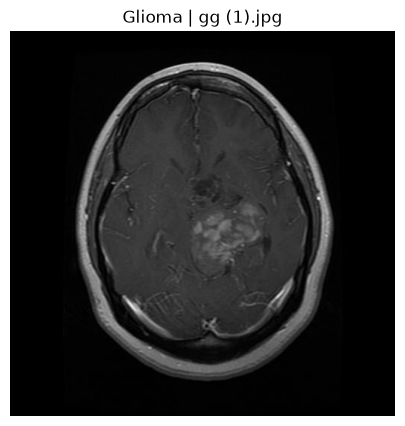

Label file: gg (1).txt
0 0.567383 0.519531 0.189453 0.148438



In [8]:
# Show first image in Train/Glioma
class_name = "Glioma"
img_path = DATA_DIR / "Train" / class_name / "images"
label_path = DATA_DIR / "Train" / class_name / "labels"

files = sorted([f for f in img_path.iterdir() if f.is_file()])
if files:
    first = files[0]
    lbl_file = label_path / (first.stem + ".txt")

    # Show image
    img = Image.open(first)
    plt.figure(figsize=(5,5))
    plt.imshow(img)
    plt.title(f"{class_name} | {first.name}")
    plt.axis("off")
    plt.show()

    # Show label content if exists
    if lbl_file.exists():
        print("Label file:", lbl_file.name)
        print(lbl_file.read_text()[:200])
    else:
        print("No label file for:", first.name)
else:
    print("No images found")

In [ ]:
CLASSIFY_TRAIN_IMG = DATA_DIR / "Train" 
CLASSIFY_VAL_IMG = DATA_DIR / "Val"
